# 06. Підсумкове порівняння моделей

Збираємо всі результати з `results/final_metrics_all.csv` у таблиці й графіки.

1. Таблиця всіх моделей на test (з кількістю хибних тривог і пропущених хворих).
2. Графік метрик усіх моделей.
3. Графік «val проти test».
4. Найкраща модель кожного підходу (вибір за val F1).
5. Стабільність найкращого рецепта за трьома seed.
6. Порівняння зі статтею Kermany et al.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("../results")
N_NORMAL, N_PNEUMONIA = 234, 390 

final = pd.read_csv(RESULTS_DIR / "final_metrics_all.csv")
final = final.drop_duplicates(["model", "split"], keep="last") 


def method(name):
    if name.startswith(("SVM", "Random Forest")):
        return "Класичний ML"
    if name.startswith("CNN"):
        return "CNN з нуля"
    if name.startswith("Ансамбль"):
        return "Ансамбль"
    return "Transfer learning"


final["method"] = final["model"].map(method)
test = final[final["split"] == "test"].drop(columns="split").set_index("model")
val = final[final["split"] == "val"].set_index("model")

test["val_f1"] = val["f1"]
test["val_accuracy"] = val["accuracy"]
test["false_alarms"] = ((1 - test["specificity"]) * N_NORMAL).round().astype(int) 
test["missed"] = ((1 - test["recall"]) * N_PNEUMONIA).round().astype(int)
print("Моделей:", len(test))

Моделей: 16


## 1. Таблиця всіх моделей на test

In [2]:
cols = ["method", "accuracy", "recall", "specificity", "f1", "auc", "false_alarms", "missed"]
table = test.sort_values("accuracy", ascending=False)[cols].round(3)
table.to_csv(RESULTS_DIR / "final_table_test.csv")
display(table)

,method,accuracy,recall,specificity,f1,auc,false_alarms,missed
model,,,,,,,,
ResNet18 ft + CLAHE + layer3,Transfer learning,0.923,0.992,0.808,0.942,0.973,45,3
ResNet18 ft + сильна аугментація,Transfer learning,0.918,0.990,0.799,0.938,0.981,47,4
Ансамбль (топ-3 за val F1),Ансамбль,0.917,0.997,0.782,0.937,0.977,51,1
ResNet18 ft + норм. яскравості + layer3,Transfer learning,0.913,0.990,0.786,0.935,0.976,50,4
Ансамбль (3 моделі з ноутбука 04),Ансамбль,0.899,0.997,0.735,0.925,0.971,62,1
"ResNet18, fine-tuning",Transfer learning,0.897,0.997,0.731,0.924,0.971,63,1
EfficientNet-B0 ft + CLAHE,Transfer learning,0.889,0.933,0.816,0.913,0.960,43,26
"ResNet18, заморожена",Transfer learning,0.872,0.954,0.735,0.903,0.951,62,18
"DenseNet121, fine-tuning",Transfer learning,0.862,0.992,0.645,0.900,0.966,83,3


## 2. Графік метрик усіх моделей на test
Три метрики: accuracy, recall (частка знайдених хворих) і specificity (частка правильно впізнаних здорових).

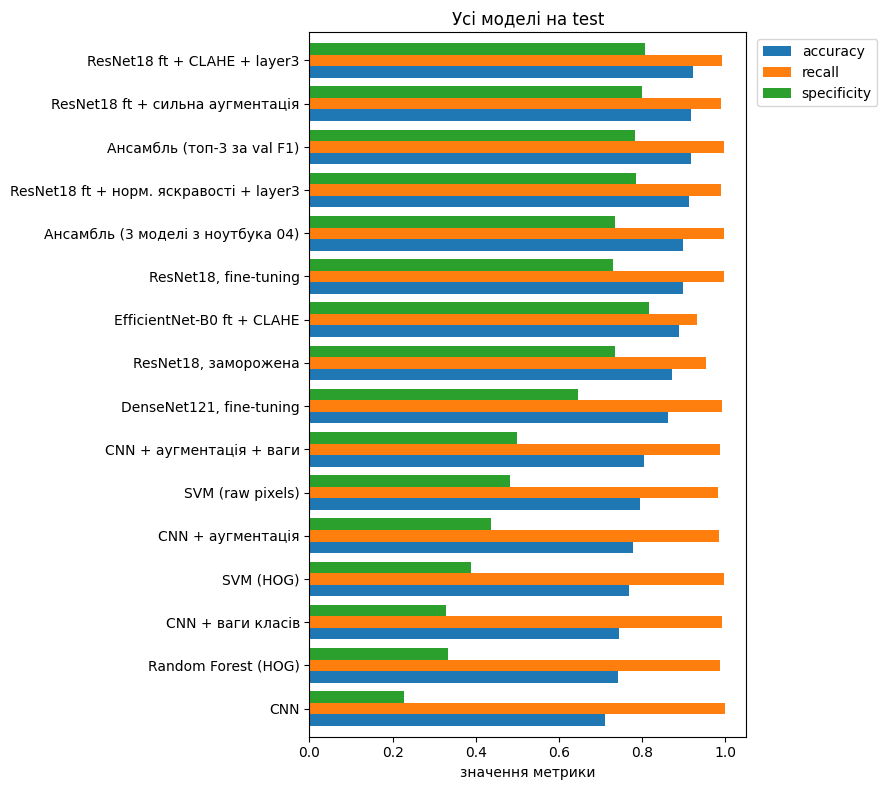

In [3]:
t = test.sort_values("accuracy")
ax = t[["accuracy", "recall", "specificity"]].plot(kind="barh", figsize=(9, 8), width=0.8)
ax.set_xlim(0, 1.05)
ax.set_xlabel("значення метрики")
ax.set_ylabel("")
ax.set_title("Усі моделі на test")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.savefig(RESULTS_DIR / "final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Бачимо, що recall майже в усіх високий, а моделі відрізняються specificity.

## 3. Розрив між val і test
Accuracy кожної моделі на val і на test. Якби val і test були однаково складними, стовпці були б майже рівні. Тут val майже в усіх ≈ 0,96-0,98, а test набагато гірший, особливо для ML і CNN.

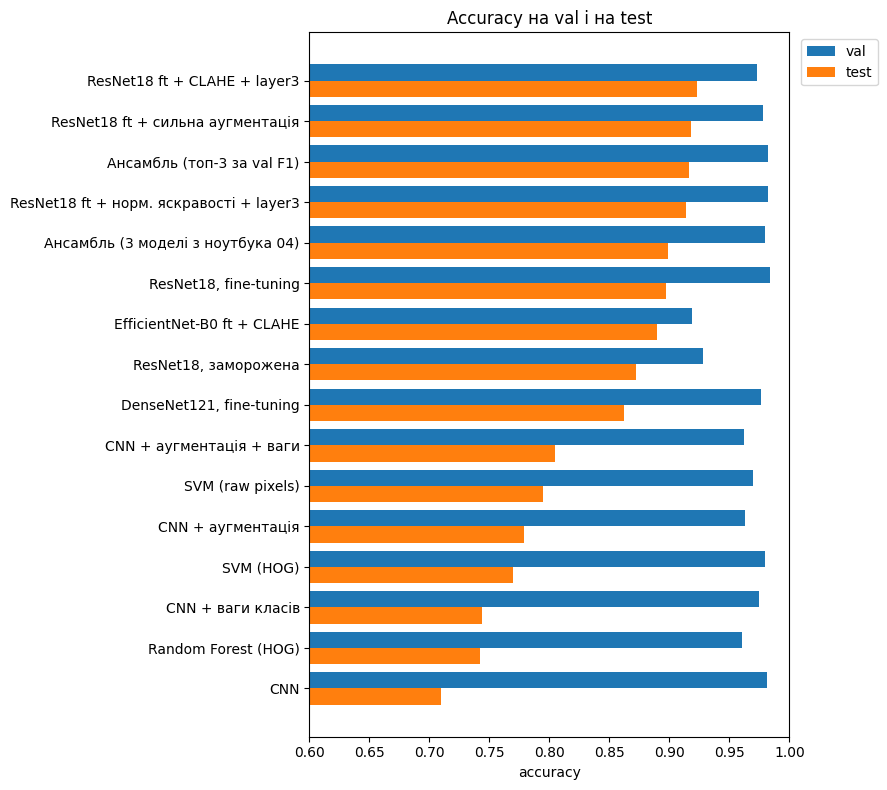

method
CNN з нуля           0.211
Transfer learning    0.066
Ансамбль             0.073
Класичний ML         0.201
Name: середній розрив val - test, dtype: float64

In [4]:
t = test.sort_values("accuracy")
pos = np.arange(len(t))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(pos + 0.2, t["val_accuracy"], height=0.4, label="val")
ax.barh(pos - 0.2, t["accuracy"], height=0.4, label="test")
ax.set_yticks(pos)
ax.set_yticklabels(t.index)
ax.set_xlim(0.6, 1.0)
ax.set_xlabel("accuracy")
ax.set_title("Accuracy на val і на test")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.savefig(RESULTS_DIR / "val_vs_test.png", dpi=150, bbox_inches="tight")
plt.show()

test["gap"] = test["val_accuracy"] - test["accuracy"]
display(test.groupby("method")["gap"].mean().round(3).rename("середній розрив val - test"))

## 4. Найкраща модель кожного підходу
Вибір за **val F1**, не за test. Але на val різниця між моделями дуже мала, тому цей вибір орієнтовний.

In [5]:
best = test.loc[test.groupby("method")["val_f1"].idxmax()]
display(best[["method", "accuracy", "recall", "specificity", "auc", "false_alarms", "missed"]].round(3))

,method,accuracy,recall,specificity,auc,false_alarms,missed
model,,,,,,,
CNN,CNN з нуля,0.710,1.000,0.226,NaN,181,0
"ResNet18, fine-tuning",Transfer learning,0.897,0.997,0.731,0.971,63,1
Ансамбль (топ-3 за val F1),Ансамбль,0.917,0.997,0.782,0.977,51,1
SVM (HOG),Класичний ML,0.769,0.997,0.389,NaN,143,1


## 5. Стабільність найкращого рецепта (3 seed)
Рецепт «ResNet18 ft + нормалізація яскравості + layer3» повторювали з трьома різними seed.

In [6]:
seeds = pd.DataFrame({
    "seed": [42, 1, 2],
    "accuracy":    [0.9134615, 0.933, 0.929],
    "recall":      [0.9897436, 0.995, 0.990],
    "specificity": [0.7863248, 0.829, 0.829],
    "auc":         [0.9757616, 0.955, 0.969],
})
seeds.to_csv(RESULTS_DIR / "seeds_pernorm.csv", index=False)

display(seeds.round(3))
display(seeds[["accuracy", "recall", "specificity", "auc"]].agg(["mean", "std"]).round(3))

,seed,accuracy,recall,specificity,auc
0,42,0.913,0.990,0.786,0.976
1,1,0.933,0.995,0.829,0.955
2,2,0.929,0.990,0.829,0.969


,accuracy,recall,specificity,auc
mean,0.925,0.992,0.815,0.967
std,0.010,0.003,0.025,0.011


## 6. Порівняння зі статтею Kermany et al. (2018)
Числа статті взяті з розділу Results (рентген, норма проти пневмонії). Автори вибирали найкращу модель за test, тому їхній результат може бути трохи оптимістичним.

In [7]:
paper = {"accuracy": 0.928, "recall": 0.932, "specificity": 0.901, "auc": 0.968}
seed_mean = seeds[["accuracy", "recall", "specificity", "auc"]].mean().to_dict()
ens = test.loc["Ансамбль (топ-3 за val F1)", ["accuracy", "recall", "specificity", "auc"]].to_dict()

comparison = pd.DataFrame(
    [paper, seed_mean, ens],
    index=["Kermany et al., 2018 (Inception V3)",
           "Наша ResNet18 ft + норм. яскравості (середнє 3 seed)",
           "Наш ансамбль (топ-3 за val F1)"],
).round(3)
comparison.to_csv(RESULTS_DIR / "comparison_with_paper.csv")
display(comparison)

,accuracy,recall,specificity,auc
"Kermany et al., 2018 (Inception V3)",0.928,0.932,0.901,0.968
Наша ResNet18 ft + норм. яскравості (середнє 3 seed),0.925,0.992,0.815,0.967
Наш ансамбль (топ-3 за val F1),0.917,0.997,0.782,0.977
